# Lab 8 – Edge Detection: Task Solution

**Objective:** Apply and compare edge detection methods using Python and OpenCV, and investigate how parameter changes affect the detected edges.

**Selected image:** `Butterfly.jpg` (a monarch butterfly on green leaves, 800 × 532 px). This is a new image, not the `kid1.jpg` image used in the original lab notebook. It suits edge detection because it has strong, well-defined boundaries (black wing veins against orange cells, white spots, the wing outline) alongside fine, low-contrast texture in the background leaves and flowers.

## Setup

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Butterfly.jpg'   # new image (not kid1.jpg)

img = cv2.imread(imgFile)
if img is None:
    raise FileNotFoundError(f"Could not read {imgFile}")

# RGB copy for display with matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
# Edge detectors work on intensity -> grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Gaussian blur reduces noise before differentiating
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

print('Image shape (H, W, C):', img.shape)

Image shape (H, W, C): (532, 800, 3)


---
# Task 1: Apply Edge Detection Methods

All three detectors use the same pre-processing as the lab notebook: convert to grayscale, then apply a 5×5 Gaussian blur.

### 1. Sobel Edge Detector
Sobel uses 3×3 kernels that combine differentiation in one direction with smoothing in the other:

```
        Gx                  Gy
  [ -1   0  +1 ]     [ -1  -2  -1 ]
  [ -2   0  +2 ]     [  0   0   0 ]
  [ -1   0  +1 ]     [ +1  +2  +1 ]

  Gradient magnitude:  |G| = sqrt(Gx^2 + Gy^2)
```

In [2]:
# Sobel: horizontal (x) and vertical (y) first derivatives
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

# Gradient magnitude = sqrt(Gx^2 + Gy^2)
sobel_combined = cv2.magnitude(sobelx, sobely)

# Convert to 8-bit for display.
# cv2.convertScaleAbs clips values above 255 to 255
# (np.uint8 alone would wrap them, e.g. 300 -> 44).
sobel_final = cv2.convertScaleAbs(sobel_combined)

### 2. Prewitt Edge Detector
Prewitt has the same structure as Sobel but uses equal weights, so it applies less smoothing:

```
        Px                  Py
  [ -1   0  +1 ]     [ -1  -1  -1 ]
  [ -1   0  +1 ]     [  0   0   0 ]
  [ -1   0  +1 ]     [ +1  +1  +1 ]
```

In [3]:
# Prewitt kernels (defined manually; no built-in in OpenCV)
kernel_x = np.array([[-1, 0, 1],
                     [-1, 0, 1],
                     [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1],
                     [ 0,  0,  0],
                     [ 1,  1,  1]], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = cv2.convertScaleAbs(prewitt_combined)

### 3. Canny Edge Detector
Canny is a multi-stage algorithm: Gaussian smoothing → Sobel gradients → non-maximum suppression (thins edges to 1 px) → double thresholding → edge tracking by hysteresis. The result is a binary edge map. Here we use the lab's suggested thresholds (100, 200), which have a 1:2 ratio.

In [4]:
canny_edges = cv2.Canny(blurred, 100, 200)

### Display: original image and the three edge maps

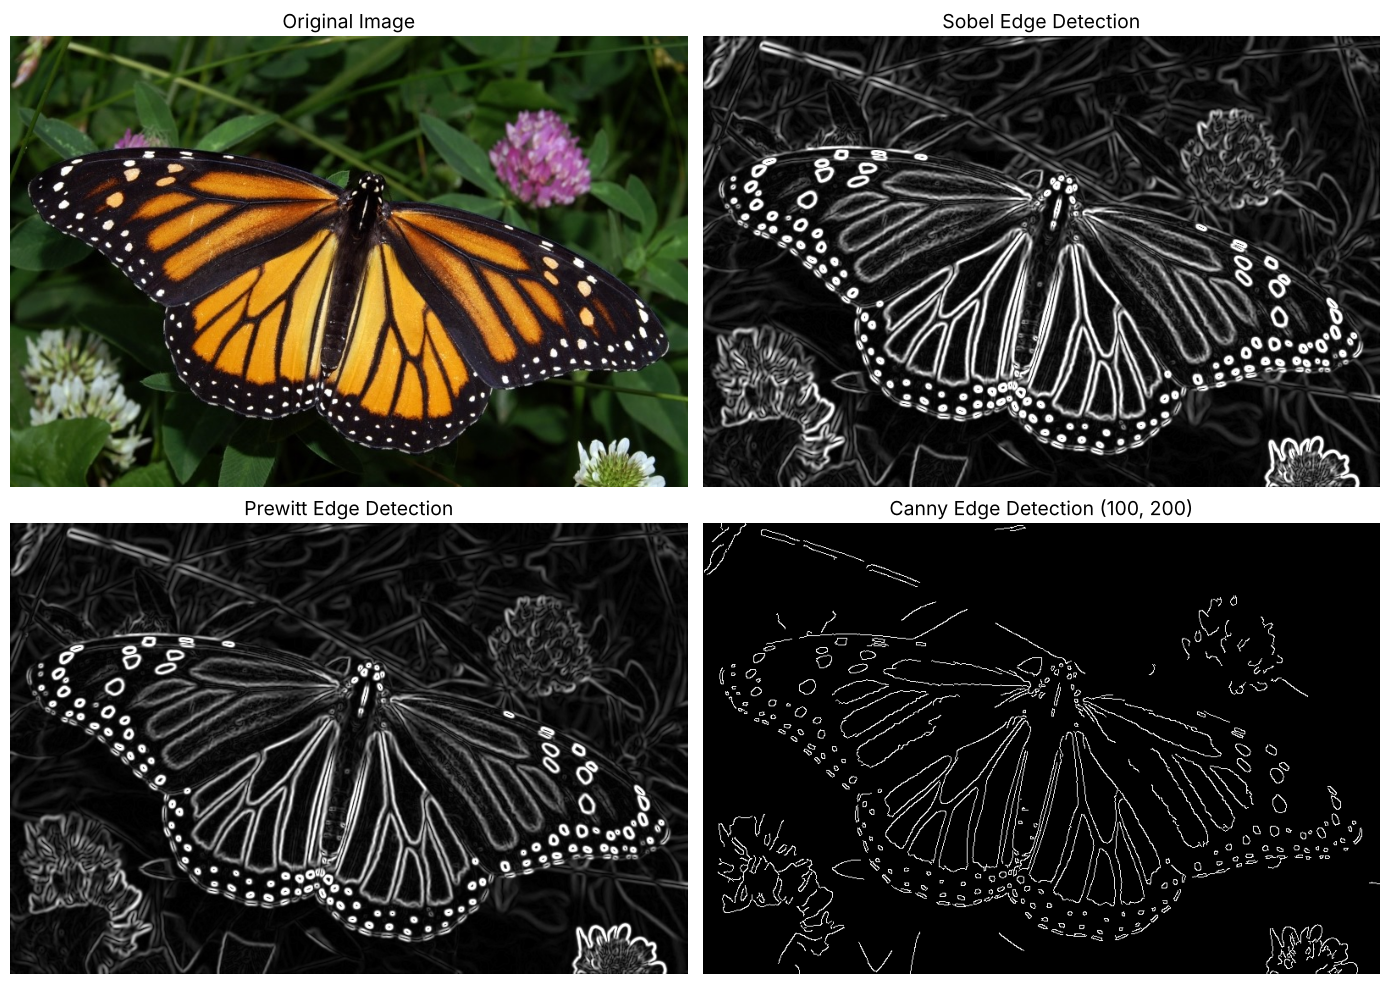

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

panels = [(img_rgb,       'Original Image'),
          (sobel_final,   'Sobel Edge Detection'),
          (prewitt_final, 'Prewitt Edge Detection'),
          (canny_edges,   'Canny Edge Detection (100, 200)')]

for ax, (im, title) in zip(axes.ravel(), panels):
    ax.imshow(im, cmap=None if im.ndim == 3 else 'gray')
    ax.set_title(title, fontsize=14)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Observations (Task 1)

- **Sobel** gives a grayscale gradient map. Edge brightness is proportional to edge strength, so the black veins and wing borders against orange appear bright, and the white spots stand out clearly. Edges are relatively thick because the 3×3 kernel responds over several pixels. Sobel's centre weight of 2 provides extra smoothing, so the background texture is slightly suppressed.
- **Prewitt** looks very similar to Sobel because the kernels share the same structure. Its responses are a little weaker in absolute value (the kernel weights sum to 3 per side instead of 4), and with equal weights it smooths less, so it is slightly more sensitive to noise and fine texture.
- **Canny** produces thin, 1-pixel, binary edges thanks to non-maximum suppression. It shows clean, continuous wing outlines, veins and spot boundaries and drops most of the weak background texture. Its output is the cleanest and most precise of the three, but it depends on the threshold choice (investigated in Task 2).

---
# Task 2: Investigate the Effect of Canny Thresholds

Canny uses two thresholds on the gradient magnitude during **hysteresis**:
- Pixels with gradient **> High** are *strong* edges and are always kept.
- Pixels with gradient **< Low** are discarded.
- Pixels **between Low and High** are *weak* edges and are kept only if they connect to a strong edge.

The pairs (30, 90) and (50, 150) use a 1:3 Low:High ratio and (100, 200) uses 1:2. All three run on the same blurred grayscale image, so only the thresholds change.

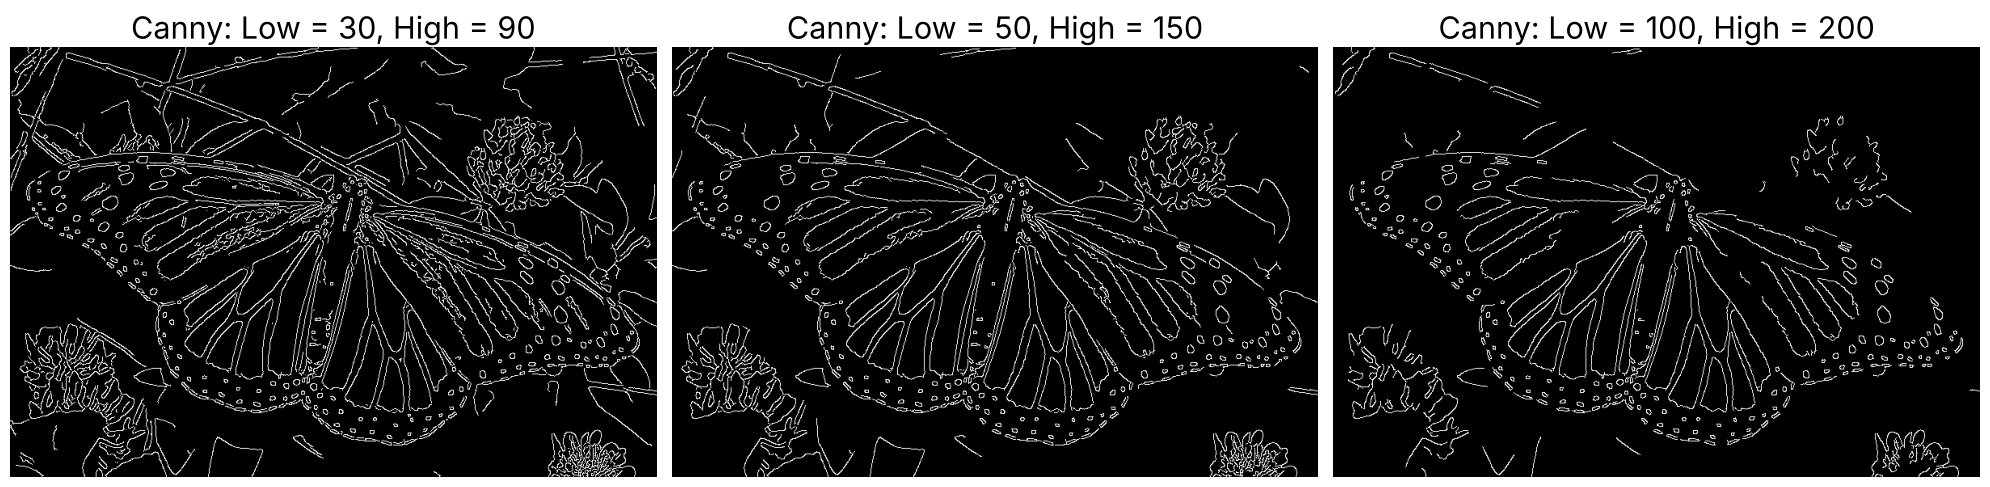

In [6]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
canny_results = [cv2.Canny(blurred, lo, hi)
                 for (lo, hi) in threshold_pairs]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (low, high), edges in zip(axes, threshold_pairs, canny_results):
    ax.imshow(edges, cmap='gray')
    ax.set_title(f'Canny: Low = {low}, High = {high}', fontsize=22)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Quantifying the effect: number of edge pixels detected

(Low, High)    Edge pixels  % of image
--------------------------------------
(30, 90)            33,792       7.94%
(50, 150)           23,434       5.51%
(100, 200)          16,823       3.95%


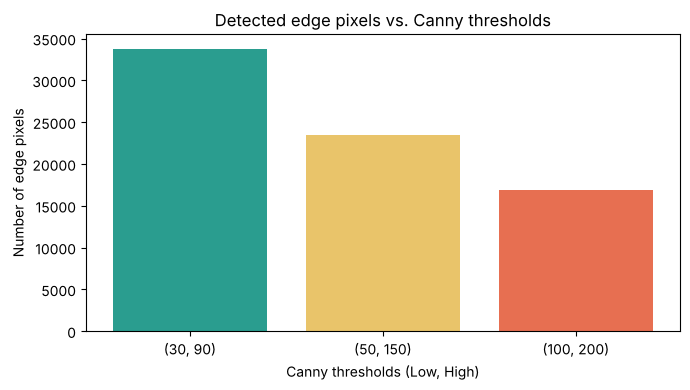

In [7]:
total = blurred.size
print(f"{'(Low, High)':<14}{'Edge pixels':>12}{'% of image':>12}")
print('-' * 38)
for (lo, hi), edges in zip(threshold_pairs, canny_results):
    n = int(np.count_nonzero(edges))
    pct = 100 * n / total
    print(f"{f'({lo}, {hi})':<14}{n:>12,}{pct:>11.2f}%")

counts = [np.count_nonzero(e) for e in canny_results]
plt.figure(figsize=(7, 4))
labels = [f'({l}, {h})' for l, h in threshold_pairs]
plt.bar(labels, counts, color=['#2a9d8f', '#e9c46a', '#e76f51'])
plt.xlabel('Canny thresholds (Low, High)')
plt.ylabel('Number of edge pixels')
plt.title('Detected edge pixels vs. Canny thresholds')
plt.tight_layout()
plt.show()

### Explanation: how the thresholds affect edges and detail

**1. Low thresholds (30, 90): the most edges and the most detail, but also the most noise.**
Because the High threshold is only 90, many moderate gradients qualify as strong edges, and the Low threshold of 30 lets even weak gradients survive if they connect to them. The map has the most edge pixels (≈ 33,800, about 7.9 % of the image). It captures fine detail such as the small white spots, thin vein lines and the texture of the leaves and clover flowers. But it also picks up background clutter and spurious short edges, which makes the main object harder to read.

**2. Medium thresholds (50, 150): a balance.**
About 23,400 edge pixels (≈ 5.5 %), roughly 30 % fewer than (30, 90). Much of the leaf and grass texture disappears, while the butterfly's wing outline, veins and spots are still continuous and clearly visible. This setting gives the best trade-off between detail and noise for this image.

**3. High thresholds (100, 200): the fewest edges, the cleanest but least detailed map.**
Only gradients above 200 seed an edge, so only strong, high-contrast boundaries remain. That leaves ≈ 16,800 edge pixels (≈ 4.0 %), about half the (30, 90) count. The background is almost completely suppressed and the main structure (wing borders, black veins against orange) is clear. However, some low-contrast detail is lost or broken into gaps, for example faint vein segments, parts of the body and some small spots.

**Conclusion.** Increasing the thresholds **reduces the number of detected edges**: the edge count falls steadily from 33.8k to 23.4k to 16.8k pixels. Higher thresholds **remove noise and fine texture, so only the strongest boundaries remain**, at the cost of losing weak but real detail. Lower thresholds **reveal more detail and finer structure but also more noise and false edges**. The **High** threshold controls which edges *start* (the strong seeds). The **Low** threshold controls how far those edges *extend* through weaker regions (edge continuity). Choosing the thresholds is therefore a trade-off between sensitivity (detail) and robustness (noise). A moderate pair such as (50, 150) works best for this butterfly image.